# Price A/B readout (CUPED skeleton)

**Question.** Does a price change produce the expected revenue change in a randomised test?

**Status.** Skeleton only. None of the candidate datasets (see `data/README.md`) has a randomised
price test with arm assignment, so no effect has been estimated. The notebook is written to run
once a real experiment log is attached in a Kaggle Notebook under `/kaggle/input/`.

**Estimand.** ΔR = E[R | arm B] − E[R | arm A], with a 95% CI. CUPED uses a pre-period revenue covariate.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import KFold, cross_val_score

from dp_abtest.guardrails import check_guardrails, pre_period_only
from dp_abtest.readout import readout

# Replace <slug> with the Kaggle dataset slug attached to the notebook.
KAGGLE_SLUG = "<slug>"
INPUT = Path(f"/kaggle/input/{KAGGLE_SLUG}/price_test.csv")
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
FIG = REPO / "reports" / "figures"
FIG.mkdir(parents=True, exist_ok=True)
SEED = 42
ARM_A, ARM_B = "A", "B"
TEST_START = "2011-01-01"  # set to the first day of the randomised period

sns.set_theme(style="whitegrid")
np.random.seed(SEED)

## 0. Method checks on simulated data (not a result)

These checks use synthetic data with a known truth. They test the estimators in `dp_abtest`
(Welch CI, CUPED variance reduction, CI calibration). They say nothing about any real price test.

In [2]:
rng = np.random.default_rng(SEED)


def simulate_test(n_per_arm: int, rho: float, effect: float) -> pd.DataFrame:
    """Two arms; outcome has sd 3 and correlation `rho` with a pre-period covariate."""
    z = rng.standard_normal(2 * n_per_arm)
    e = rng.standard_normal(2 * n_per_arm)
    y = rho * z + np.sqrt(1 - rho**2) * e
    is_b = np.repeat([False, True], n_per_arm)
    return pd.DataFrame({
        "arm": np.where(is_b, ARM_B, ARM_A),
        "revenue": 10 + 3 * y + effect * is_b,
        "pre_revenue": 10 + 3 * z,
    })

unadjusted    0.1297
cuped         0.0968


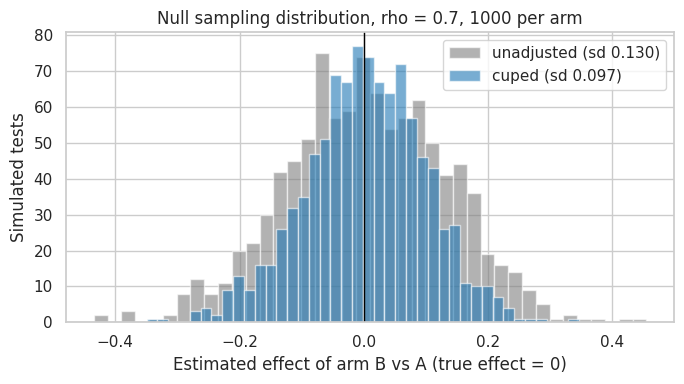

In [3]:
# Sampling distribution of the estimate under no effect (1000 simulated tests of 1000 per arm).
null_rows = []
for _ in range(1000):
    res = readout(simulate_test(1000, rho=0.7, effect=0.0), "arm", "revenue", ARM_A, ARM_B,
                  covariate="pre_revenue")
    null_rows.append({"unadjusted": res["unadjusted"].estimate, "cuped": res["cuped"].estimate})
null_df = pd.DataFrame(null_rows)
print(null_df.std().round(4).to_string())

fig, ax = plt.subplots(figsize=(7, 4))
for col, color in (("unadjusted", "tab:gray"), ("cuped", "tab:blue")):
    ax.hist(null_df[col], bins=40, alpha=0.6, color=color, label=f"{col} (sd {null_df[col].std():.3f})")
ax.axvline(0, color="black", lw=1)
ax.set_xlabel("Estimated effect of arm B vs A (true effect = 0)")
ax.set_ylabel("Simulated tests")
ax.set_title("Null sampling distribution, rho = 0.7, 1000 per arm")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "sim_null_sampling.png", dpi=120)
plt.show()

 rho  simulated  theory
0.00      1.003   1.000
0.15      0.987   0.978
0.30      0.899   0.910
0.45      0.787   0.798
0.60      0.650   0.640
0.75      0.418   0.438
0.90      0.207   0.190


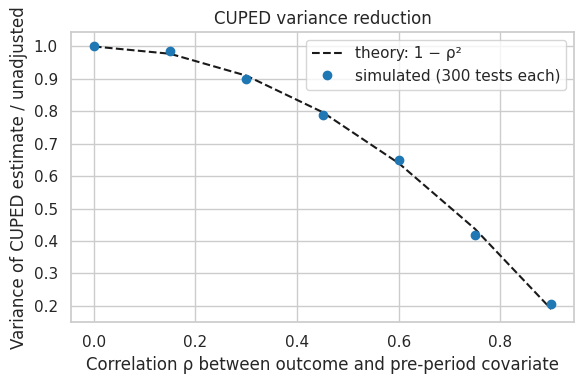

In [4]:
# Variance reduction from CUPED against the theoretical 1 - rho^2, over a grid of correlations.
rhos = np.round(np.arange(0.0, 0.95, 0.15), 2)
vr_rows = []
for rho in rhos:
    est = [readout(simulate_test(1000, rho=rho, effect=0.0), "arm", "revenue", ARM_A, ARM_B,
                   covariate="pre_revenue") for _ in range(300)]
    vr_rows.append({"rho": rho,
                    "simulated": np.var([r["cuped"].estimate for r in est])
                                 / np.var([r["unadjusted"].estimate for r in est]),
                    "theory": 1 - rho**2})
vr = pd.DataFrame(vr_rows)
print(vr.round(3).to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(vr["rho"], vr["theory"], "k--", label="theory: 1 − ρ²")
ax.plot(vr["rho"], vr["simulated"], "o", color="tab:blue", label="simulated (300 tests each)")
ax.set_xlabel("Correlation ρ between outcome and pre-period covariate")
ax.set_ylabel("Variance of CUPED estimate / unadjusted")
ax.set_title("CUPED variance reduction")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "sim_variance_ratio.png", dpi=120)
plt.show()

 n_per_arm  unadjusted  cuped
       200       0.970  0.960
       500       0.964  0.960
      1000       0.948  0.930
      2000       0.944  0.948


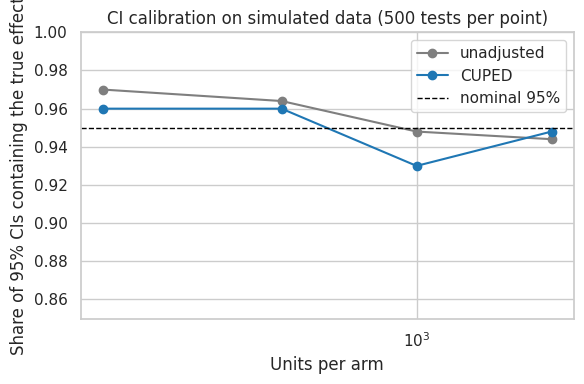

In [5]:
# Coverage of the nominal 95% CI for a known effect, by sample size per arm (500 tests each).
EFFECT = 0.2
cov_rows = []
for n in (200, 500, 1000, 2000):
    hits = {"unadjusted": 0, "cuped": 0}
    for _ in range(500):
        res = readout(simulate_test(n, rho=0.7, effect=EFFECT), "arm", "revenue", ARM_A, ARM_B,
                      covariate="pre_revenue")
        for label in hits:
            e = res[label]
            hits[label] += e.ci_low <= EFFECT <= e.ci_high
    cov_rows.append({"n_per_arm": n, **{k: v / 500 for k, v in hits.items()}})
cov = pd.DataFrame(cov_rows)
print(cov.to_string(index=False))

fig, ax = plt.subplots(figsize=(6, 4))
ax.plot(cov["n_per_arm"], cov["unadjusted"], "o-", color="tab:gray", label="unadjusted")
ax.plot(cov["n_per_arm"], cov["cuped"], "o-", color="tab:blue", label="CUPED")
ax.axhline(0.95, color="black", ls="--", lw=1, label="nominal 95%")
ax.set_ylim(0.85, 1.0)
ax.set_xscale("log")
ax.set_xlabel("Units per arm")
ax.set_ylabel("Share of 95% CIs containing the true effect")
ax.set_title("CI calibration on simulated data (500 tests per point)")
ax.legend()
fig.tight_layout()
fig.savefig(FIG / "sim_ci_coverage.png", dpi=120)
plt.show()

## 1. Load the test table

Expected columns: `unit_id`, `arm` (A or B), `assigned_at`, `pre_revenue` (pre-period covariate),
`pre_period_at` (timestamp of the covariate observation, must be before the test start),
`revenue` (outcome per unit over the test window).

In [6]:
if not INPUT.exists():
    raise FileNotFoundError(
        f"{INPUT} not found. Attach a randomised price-test dataset with slug {KAGGLE_SLUG!r} "
        "to this Kaggle Notebook (see data/README.md)."
    )

df = pd.read_csv(INPUT, parse_dates=["assigned_at", "pre_period_at"])
df = df[df["arm"].isin([ARM_A, ARM_B])].dropna(subset=["revenue", "pre_revenue"]).copy()
counts = df["arm"].value_counts()
print(counts.to_string())

FileNotFoundError: /kaggle/input/<slug>/price_test.csv not found. Attach a randomised price-test dataset with slug '<slug>' to this Kaggle Notebook (see data/README.md).

## 2. Guardrails

The effect is reported only if these pass: minimum arm size, no sample ratio mismatch,
and the covariate is measured before the test started.

In [7]:
pre_ok = pre_period_only(df["pre_period_at"], TEST_START)
guard = check_guardrails(int(counts[ARM_A]), int(counts[ARM_B]), min_per_arm=1000,
                         expected_share_b=0.5, pre_period_ok=pre_ok)
print(guard.checks, guard.details)
assert guard.passed, "Guardrails failed; do not report an effect."

NameError: name 'df' is not defined

## 3. Unadjusted and CUPED effect

In [8]:
res = readout(df, "arm", "revenue", ARM_A, ARM_B, covariate="pre_revenue")
rows = []
for label in ("unadjusted", "cuped"):
    e = res[label]
    rows.append({"estimator": label, "effect": e.estimate, "ci_low": e.ci_low,
                 "ci_high": e.ci_high, "p_value": e.p_value})
summary = pd.DataFrame(rows)
print(summary.to_string(index=False))
print(f"theta = {res['theta']:.4f}; CUPED variance ratio = {res['variance_ratio']:.3f}")

NameError: name 'df' is not defined

## 4. Cross-checks

A regression-adjusted estimate with HC3 errors, and how well the covariate predicts the outcome
out of fold (cross-validated R², seed 42).

In [9]:
ols = smf.ols("revenue ~ C(arm) + pre_revenue", data=df).fit(cov_type="HC3")
ci = ols.conf_int().loc[f"C(arm)[T.{ARM_B}]"]
print(f"OLS with covariate: effect {ols.params[f'C(arm)[T.{ARM_B}]']:.4f}, 95% CI [{ci[0]:.4f}, {ci[1]:.4f}]")

cv = cross_val_score(LinearRegression(), df[["pre_revenue"]], df["revenue"],
                     cv=KFold(5, shuffle=True, random_state=SEED), scoring="r2")
print(f"covariate out-of-fold R² = {cv.mean():.3f}")

NameError: name 'df' is not defined

## 5. Figure: arm-level revenue with CI

In [10]:
means = df.groupby("arm")["revenue"].agg(["mean", "sem"]).reindex([ARM_A, ARM_B])
fig, ax = plt.subplots(figsize=(6, 4))
ax.errorbar(means.index, means["mean"], yerr=1.96 * means["sem"], fmt="o", capsize=6)
ax.set_ylabel("Revenue per unit (mean, 95% CI)")
ax.set_title("Randomised price test: arm-level revenue (dataset: " + KAGGLE_SLUG + ")")
fig.tight_layout()
fig.savefig(FIG / "arm_revenue_ci.png", dpi=120)
plt.show()

NameError: name 'df' is not defined